# Are hand synergies shared across people? Pose structure vs EMG structure in 12 users

The project compresses the hand pose into a few latent dimensions (PCA / autoencoder) before decoding it from the
wrist EMG. All previous notebooks used **one person** (the mini dataset). Here we ask the computational-neuroscience
version of the question with **12 people**:

> Is there a **common control vocabulary** for the hand? If the low-dimensional pose "synergies" come from shared
> neural control and shared hand mechanics, the pose subspace should be **nearly the same in everybody**. The EMG
> patterns that produce those poses depend on each person's anatomy and on where the band sits on the wrist, so the
> EMG subspace should be **more person-specific**.

| | question | test |
|---|---|---|
| 1 | Is the pose subspace shared across people? | per-user PCA of the 20 angles; cross-user subspace overlap; leave-one-user-out reconstruction |
| 2 | Is the EMG subspace shared across people? | per-user PCA of the 16 log-envelopes; same tests, plus channel-rotation and channel-shuffle nulls |
| 3 | Is pose structure **more** shared than EMG structure? | overlap normalised by chance and by within-person reliability; bootstrap over users |
| 4 | Does every person decode the same pose directions? | per-user reduced-rank regression EMG → pose; rank needed, overlap of decodable subspaces |

**Data.** 12 users from the full emg2pose dataset (4 `val` users, 4 test-only held-out users, 4 `train` users whose held-out-stage recordings are in `test`),
13 structured stages that both recording protocols share, both hands, two sessions of each stage (the band is put
on again between sessions). The files were pulled out of the 431 GiB tar with HTTP range requests into
`~/emg2pose_dataset_partial`. **This notebook does not run on Colab** (and not locally either without that folder):
it analyses an 11.5 GB subset (624 recordings; users drawn at random, with a fixed seed, among those with two
sessions of every stage), not the mini dataset.

Everything at 50 Hz, IK-failure frames dropped (mask eroded by 150 ms), `unconstrained` excluded (not downloaded).

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import json
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.linalg import subspace_angles

from semg2pose.data import FS, JOINT_NAMES, load_session
from semg2pose.signals import log_envelope

warnings.filterwarnings("ignore")
DATA_DIR = Path.home() / "emg2pose_dataset_partial"
METADATA_CSV = Path.home() / "emg2pose_metadata.csv"
EXPORT_DIR = os.environ.get("CROSS_USER_EXPORT")   # optional: where to save key figures + JSON
plt.rcParams["figure.dpi"] = 100
STEP = 40            # 2 kHz -> 50 Hz
FS_L = FS // STEP
LAGS = [0, 2, 5, 10, 15]
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9AA1B0"
D_POSE, D_EMG = 20, 16
rng = np.random.default_rng(0)
assert DATA_DIR.exists(), f"{DATA_DIR} not found: this notebook needs the multi-user subset (see the first cell)"

## 0. Data: who and what

Each recording gets a **session half**: for every (user, stage, hand) the first recording goes to half A and the
second (a different session, band re-donned) to half B. Both halves therefore contain the same tasks. We also split
every recording in time (first vs second half of the recording) to get a within-session split with the band in the
same place. These splits give the **within-person reliability**, the ceiling that cross-person overlaps are compared
with.

In [3]:
meta_csv = pd.read_csv(METADATA_CSV)
files = sorted(DATA_DIR.glob("*.hdf5"))
info = meta_csv.set_index("filename").loc[[f.stem for f in files]].reset_index()
info["path"] = files
info = info[info.stage != "unconstrained"].sort_values("start").reset_index(drop=True)
info["half"] = info.groupby(["user", "stage", "side"]).cumcount().map({0: "A", 1: "B"})
info = info.dropna(subset=["half"])


def featurize(path):
    emg, angles, ok, _ = load_session(path)
    good = ~np.convolve(~ok, np.ones(601), mode="same").astype(bool)[::STEP]
    return {"env": log_envelope(emg, band=(20, 450), window_s=0.05)[::STEP].astype(np.float32),
            "ang": np.degrees(angles[::STEP]).astype(np.float32), "ok": good}


feats = Parallel(n_jobs=8)(delayed(featurize)(p) for p in info.path)
recs = []
for (_, row), f in zip(info.iterrows(), feats):
    T = len(f["ok"])
    f["late"] = np.arange(T) >= T // 2           # time split within the recording
    recs.append({**f, "user": row.user, "stage": row.stage, "side": row.side, "half": row.half,
                 "session": row.session, "split": row.split})

USERS = sorted(info.user.unique(), key=lambda u: (info[info.user == u].split.iloc[0], u))
split_of = {u: ("train" if "train" in set(info[info.user == u].split) else info[info.user == u].split.iloc[0]) for u in USERS}
LABEL = {u: f"{u[:4]} ({split_of[u]})" for u in USERS}
N = len(USERS)
summary = pd.DataFrame([{"user": u, "split": split_of[u],
                         "recordings": sum(r["user"] == u for r in recs),
                         "sessions": info[info.user == u].session.nunique(),
                         "stages": info[info.user == u].stage.nunique(),
                         "valid minutes": sum(r["ok"].sum() for r in recs if r["user"] == u) / FS_L / 60}
                        for u in USERS]).set_index("user")
print(summary.round(1).to_string())
print(f"\n{len(recs)} recordings, {summary['valid minutes'].sum() / 60:.1f} valid hours, stages: {sorted(info.stage.unique())}")

            split  recordings  sessions  stages  valid minutes
user                                                          
0219627c14   test          52         4      13           42.8
05026be68a   test          52         4      13           40.4
7e08fa55fd   test          52         4      13           53.3
9fc18a9307   test          52         4      13           45.2
84a77feea6  train          52         4      13           48.6
969483f088  train          52         4      13           40.6
b1284f4935  train          52         4      13           40.0
f0ff207f52  train          52         4      13           48.1
2af4aec870    val          52         4      13           43.7
7016fd5330    val          52         4      13           42.1
737fb9d2eb    val          52         4      13           47.0
e86f1eaf2f    val          52         4      13           46.1

624 recordings, 9.0 valid hours, stages: ['CountingUpDownFaceSideAway', 'FingerAbductionSeries', 'FingerFreeform', 'F

Helpers. `data(u, key, ...)` returns the valid frames of one user (optionally one session half, one time half,
one hand or a subset of stages). Subspace overlap = mean cos² of the principal angles between two k-dimensional
subspaces, which equals ‖U_kᵀV_k‖²_F / k (1 = identical; k/D = expected for random subspaces).

In [4]:
def data(u, key, half=None, late=None, side=None, stages=None):
    out = []
    for r in recs:
        if r["user"] != u or (half and r["half"] != half) or (side and r["side"] != side):
            continue
        if stages is not None and r["stage"] not in stages:
            continue
        m = r["ok"] if late is None else r["ok"] & (r["late"] == late)
        out.append(r[key][m])
    return np.vstack(out).astype(np.float64)


def pca(X):
    """Eigenvalues (descending) and eigenvectors (columns) of the covariance of X."""
    Xc = X - X.mean(0)
    ev, U = np.linalg.eigh(Xc.T @ Xc / len(Xc))
    return ev[::-1], U[:, ::-1]


def participation_ratio(ev):
    return ev.sum() ** 2 / (ev ** 2).sum()


def overlap(U, V, k):
    return np.linalg.norm(U[:, :k].T @ V[:, :k]) ** 2 / k


def norm_cov(X):
    Xc = X - X.mean(0)
    C = Xc.T @ Xc / len(Xc)
    return C / np.trace(C)


# sanity check of the overlap formula against scipy's principal angles
_A, _B = np.linalg.qr(rng.normal(size=(20, 5)))[0], np.linalg.qr(rng.normal(size=(20, 5)))[0]
assert np.isclose(overlap(_A, _B, 5), np.mean(np.cos(subspace_angles(_A, _B)) ** 2))

# all the PCA bases we need, for pose ("ang") and EMG ("env")
basis = {}
for key in ["ang", "env"]:
    for u in USERS:
        basis[key, u, "all"] = pca(data(u, key))
        for h in "AB":
            basis[key, u, h] = pca(data(u, key, half=h))
        for late in (False, True):
            basis[key, u, "late" if late else "early"] = pca(data(u, key, late=late))
        for side in ("left", "right"):
            basis[key, u, side] = pca(data(u, key, side=side))

## 1. Pose: is the hand-pose subspace the same in everybody?

**What we expect.** One person's pose is low-dimensional (a few PCs describe it, `joint_space_manifold.ipynb`). If
that structure is a shared vocabulary, (a) every person needs about the same number of dimensions and (b) the top
PCs span almost the same subspace in every person, close to the within-person (session A vs session B) reliability.
All users did the same 13 tasks, so a shared task set alone already pushes towards shared structure: this is a test
of *invariance under the same instructions*, not of spontaneous behaviour.

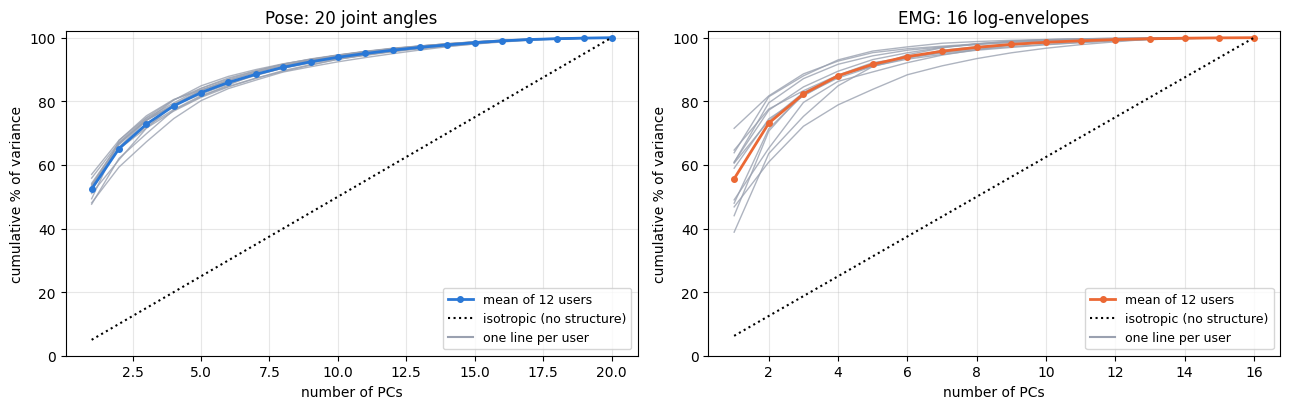

Pose spectrum per user:
                PR  PC1 %  k for 80 %  k for 90 %  k for 95 %
user                                                        
0219 (test)   3.2   53.3           5           8          11
0502 (test)   3.2   53.2           5           9          12
7e08 (test)   3.8   47.6           5           8          11
9fc1 (test)   3.2   53.6           5           8          12
84a7 (train)  3.0   55.8           5           8          11
9694 (train)  3.1   54.2           5           8          12
b128 (train)  3.8   48.1           5           9          13
f0ff (train)  3.2   53.8           5           9          12
2af4 (val)    3.5   49.3           4           8          12
7016 (val)    3.3   52.1           4           8          11
737f (val)    2.9   57.0           4           8          11
e86f (val)    3.4   51.0           5           8          11

Pose PR across users: 3.28 ± 0.29 (mean ± SD), range 2.86-3.81


In [5]:
def spectrum_table(key, D):
    rows = []
    for u in USERS:
        ev = basis[key, u, "all"][0]
        cum = np.cumsum(ev) / ev.sum()
        rows.append({"user": LABEL[u], "PR": participation_ratio(ev), "PC1 %": 100 * cum[0],
                     "k for 80 %": int(np.argmax(cum >= 0.8) + 1), "k for 90 %": int(np.argmax(cum >= 0.9) + 1),
                     "k for 95 %": int(np.argmax(cum >= 0.95) + 1)})
    return pd.DataFrame(rows).set_index("user")


spec_pose, spec_emg = spectrum_table("ang", D_POSE), spectrum_table("env", D_EMG)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key, D, col, title in [(axs[0], "ang", D_POSE, BLUE, "Pose: 20 joint angles"),
                               (axs[1], "env", D_EMG, ORANGE, "EMG: 16 log-envelopes")]:
    curves = np.array([np.cumsum(basis[key, u, "all"][0]) / basis[key, u, "all"][0].sum() for u in USERS])
    for c in curves:
        ax.plot(range(1, D + 1), 100 * c, color=GREY, lw=1, alpha=0.8)
    ax.plot(range(1, D + 1), 100 * curves.mean(0), "o-", color=col, lw=2, ms=4, label=f"mean of {N} users")
    ax.plot(range(1, D + 1), 100 * np.arange(1, D + 1) / D, ":", color="k", label="isotropic (no structure)")
    ax.plot([], [], color=GREY, label="one line per user")
    ax.set_xlabel("number of PCs"); ax.set_ylabel("cumulative % of variance"); ax.set_title(title)
    ax.set_ylim(0, 102); ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Pose spectrum per user:\n", spec_pose.round(1).to_string())
print(f"\nPose PR across users: {spec_pose.PR.mean():.2f} ± {spec_pose.PR.std():.2f} (mean ± SD), "
      f"range {spec_pose.PR.min():.2f}-{spec_pose.PR.max():.2f}")

**What we see.** The pose spectrum is strikingly similar in all 12 people: participation ratio 3.28 ± 0.29
(range 2.86-3.81), PC1 holds 48-57 % of the variance, and every user needs 4-5 PCs for 80 % and 8-9 PCs for 90 %.
The EMG spectrum (right panel; numbers in section 2) is lower-dimensional but much more variable across people:
PR 2.88 ± 0.72 (1.89-4.15), PC1 39-72 %.

Now the subspaces. For k = 3, 5, 8 we compute, for every pair of users, the overlap of their top-k pose PCs.
Reference levels:

- **random**: k/20;
- **joint-shuffle null**: overlap after randomly permuting the 20 joints of one user (keeps each person's spectrum,
  destroys the correspondence between joints);
- **finger-permutation null** (a *structured* null): swap the four fingers (index, middle, ring, little) of one
  user, all 23 non-identity orders, thumb kept. This keeps the generic structure (within-finger MCP-PIP-DIP coupling,
  "all fingers flex together") and only breaks *which* finger does what. It is the pose analogue of the band-rotation
  null used for the EMG below;
- **within-person ceiling**: session half A vs half B of the same person (same tasks, a different session).

To compare like with like, the cross-person overlap is also computed between halves (each user's A and B halves
against the other's A and B halves), so that both numbers come from the same amount of data.

In [6]:
KS = [3, 5, 8]
FINGER_BLOCKS = [list(range(4 + 4 * f, 8 + 4 * f)) for f in range(4)]          # index, middle, ring, little
FINGER_PERMS = [np.array(list(range(4)) + sum((FINGER_BLOCKS[i] for i in p), []))
                for p in __import__("itertools").permutations(range(4)) if p != (0, 1, 2, 3)]
ROTATIONS = [(np.arange(D_EMG) - s) % D_EMG for s in range(1, D_EMG)]            # U[perm] == np.roll(U, s, axis=0)


def overlap_stats(key, D, struct_perms, ks=KS, n_shuffle=100):
    out = {}
    for k in ks:
        full = np.array([[overlap(basis[key, a, "all"][1], basis[key, b, "all"][1], k) for b in USERS] for a in USERS])
        half = np.array([[np.mean([overlap(basis[key, a, ha][1], basis[key, b, hb][1], k) for ha in "AB" for hb in "AB"])
                          for b in USERS] for a in USERS])
        within_session = np.array([overlap(basis[key, u, "A"][1], basis[key, u, "B"][1], k) for u in USERS])
        within_time = np.array([overlap(basis[key, u, "early"][1], basis[key, u, "late"][1], k) for u in USERS])
        shuffle = np.array([[np.mean([overlap(basis[key, a, "all"][1], basis[key, b, "all"][1][rng.permutation(D)], k)
                                      for _ in range(n_shuffle)]) if a != b else np.nan for b in USERS] for a in USERS])
        struct_all = np.array([[[overlap(basis[key, a, "all"][1], basis[key, b, "all"][1][p], k) for p in struct_perms]
                                for b in USERS] for a in USERS])
        out[k] = {"full": full, "half": half, "within_session": within_session, "within_time": within_time,
                  "shuffle": shuffle, "struct": struct_all.mean(-1), "struct_all": struct_all, "random": k / D}
        # diagonal of "struct" = the same user with fingers swapped / band rotated
    return out


off = ~np.eye(N, dtype=bool)
ov_pose = overlap_stats("ang", D_POSE, FINGER_PERMS)
rows = []
for k, s in ov_pose.items():
    rows.append({"k": k, "random": s["random"], "joint-shuffle null": np.nanmean(s["shuffle"]),
                 "finger-permutation null": s["struct"][off].mean(),
                 "cross-user (full data)": s["full"][off].mean(), "cross-user (halves)": s["half"][off].mean(),
                 "within-user, other session": s["within_session"].mean(),
                 "within-user, same session (time split)": s["within_time"].mean(),
                 "min cross-user pair": s["full"][off].min()})
tab_pose = pd.DataFrame(rows).set_index("k")
print(tab_pose.round(3).to_string())

   random  joint-shuffle null  finger-permutation null  cross-user (full data)  cross-user (halves)  within-user, other session  within-user, same session (time split)  min cross-user pair
k                                                                                                                                                                                           
3    0.15               0.212                    0.650                   0.803                0.781                       0.930                                   0.758                0.607
5    0.25               0.277                    0.611                   0.793                0.778                       0.919                                   0.782                0.699
8    0.40               0.409                    0.653                   0.820                0.815                       0.933                                   0.838                0.715


**What we see.** The top-3 pose subspace of two different people overlaps 0.80 on average (0.78 on session
halves; worst pair 0.61), against 0.93 for the same person in another session and 0.15 for random subspaces. The
joint-shuffle null is near chance (0.21), so this is not a spectrum artefact. But the **finger-permutation null is
already 0.65**: a large part of what people share is generic (the whole hand closing and opening looks the same
whichever finger is called "index"). Cross-person overlap is above that structured floor (0.78 vs 0.65) and below
the within-person ceiling (0.93): people share the generic synergies *and* a good part of the finger-specific
ones, but not all. Same picture at k = 5 (0.78 / 0.92 / null 0.61) and k = 8 (0.82 / 0.93 / null 0.65).

Note the time split (first vs second half of each recording): 0.76, *lower* than the cross-session split. The two
halves of a recording contain different gestures, so the pose subspace depends on *what* is done. Section 3b
follows this up.

**Leave-one-user-out reconstruction.** A stricter, more practical test: can a PCA basis fitted on the **other 11
users** compress a new person's pose as well as that person's own basis? For each held-out user and each session
half we reconstruct the angles from the top-k PCs (data centred on that half's own mean, so only the subspace
matters) with three bases:

- **own, in-sample**: PCA of the same data (optimistic floor);
- **own, other session**: PCA of the user's other session half (an honest within-person baseline);
- **other users**: PCA of the average (trace-normalised) covariance of the other 11 users.

Error = mean absolute error over joints and frames, in degrees.

In [7]:
KS_REC = [2, 4, 6, 8, 12]


def louo(key, ks=KS_REC, rotate_null=False):
    """Per (user, k): MAE and fraction of variance explained for own-in-sample, own-other-half, other-users bases."""
    rows = []
    for u in USERS:
        C_oth = np.mean([norm_cov(data(v, key)) for v in USERS if v != u], axis=0)
        U_oth = np.linalg.eigh(C_oth)[1][:, ::-1]
        for h, h_other in [("A", "B"), ("B", "A")]:
            X = data(u, key, half=h)
            Xc = X - X.mean(0)
            tot = (Xc ** 2).sum()
            bases = {"own, in-sample": basis[key, u, h][1], "own, other session": basis[key, u, h_other][1],
                     "other users": U_oth}
            if rotate_null:
                D = X.shape[1]
                bases.update({f"other users, channels rotated by {s}": np.roll(U_oth, s, axis=0) for s in range(1, D)})
            for name, U in bases.items():
                for k in ks:
                    R = Xc - Xc @ U[:, :k] @ U[:, :k].T
                    rows.append({"user": u, "half": h, "basis": name, "k": k,
                                 "MAE": np.abs(R).mean(), "VE": 1 - (R ** 2).sum() / tot})
            for k in ks:
                rows.append({"user": u, "half": h, "basis": "none (mean only)", "k": k,
                             "MAE": np.abs(Xc).mean(), "VE": 0.0})
    df = pd.DataFrame(rows)
    return df.groupby(["user", "basis", "k"])[["MAE", "VE"]].mean().reset_index()


rec_pose = louo("ang")
mae_pose = rec_pose.pivot_table(index="k", columns="basis", values="MAE", aggfunc="mean")
ve_pose = rec_pose.pivot_table(index="k", columns="basis", values="VE", aggfunc="mean")
print("Pose reconstruction MAE (degrees), mean over users:\n", mae_pose.round(2).to_string())
print("\nPose variance explained, mean over users:\n", ve_pose.round(3).to_string())
gap = rec_pose[rec_pose.basis == "other users"].set_index(["user", "k"]).MAE - \
      rec_pose[rec_pose.basis == "own, other session"].set_index(["user", "k"]).MAE
print("\nExtra MAE of the other-users basis vs own other-session basis (degrees): mean (worst user)")
print(gap.groupby("k").agg(["mean", "max"]).round(2).to_string())

Pose reconstruction MAE (degrees), mean over users:
 basis  none (mean only)  other users  own, in-sample  own, other session
k                                                                       
2                 19.44        10.97           10.65               10.78
4                 19.44         9.04            8.42                8.62
6                 19.44         7.41            6.79                7.03
8                 19.44         6.07            5.45                5.70
12                19.44         4.00            3.35                3.56

Pose variance explained, mean over users:
 basis  none (mean only)  other users  own, in-sample  own, other session
k                                                                       
2                   0.0        0.634           0.653               0.646
4                   0.0        0.761           0.788               0.778
6                   0.0        0.834           0.862               0.852
8                   0.0    

**What we see.** A pose basis from 11 other people is almost as good as the person's own basis from another
session: at k = 4 the error is 9.04° vs 8.62° (in-sample floor 8.42°; 19.4° with no compression), at k = 8 6.07°
vs 5.70°. The extra error is 0.2-0.45° on average and at most ~1° for the worst user. In variance terms the
other-users basis reaches 98-99 % of what the own basis explains (worst user 95 %). **For the project: a
population PCA latent transfers to a new person with a negligible loss.**

## 2. EMG: is the muscle-activity subspace the same in everybody?

**What we expect.** EMG patterns depend on the forearm anatomy (muscle sizes, fat layer) and on band placement:
a rotation of the band by one electrode shifts every pattern by one channel. So we expect lower cross-user overlap
than for the pose, *relative to the within-person reliability*.

**A trap.** EMG subspaces are spatially smooth: neighbouring electrodes see the same muscles (crosstalk), and the
first PC is usually "everything up together" (overall effort), which is the same in any rotation of the band. Two
random people can therefore share a lot of EMG subspace **without any anatomical correspondence between their
channels**. Two nulls measure how much overlap this generic structure produces:

- **rotation null**: circularly shift the channel index of one user by s = 1…15 electrodes (a band put on rotated)
  and average the overlap over s. If the observed overlap at s = 0 is not above this, the channel correspondence
  between people carries no extra information;
- **channel-shuffle null**: randomly permute one user's channels (destroys smoothness too).

In [8]:
print("EMG spectrum per user:\n", spec_emg.round(1).to_string())
print(f"\nEMG PR across users: {spec_emg.PR.mean():.2f} ± {spec_emg.PR.std():.2f}, "
      f"range {spec_emg.PR.min():.2f}-{spec_emg.PR.max():.2f}")
ov_emg = overlap_stats("env", D_EMG, ROTATIONS)
rows = []
for k, s in ov_emg.items():
    rows.append({"k": k, "random": s["random"], "channel-shuffle null": np.nanmean(s["shuffle"]),
                 "rotation null": s["struct"][off].mean(),
                 "cross-user (full data)": s["full"][off].mean(), "cross-user (halves)": s["half"][off].mean(),
                 "within-user, other session": s["within_session"].mean(),
                 "within-user, same session (time split)": s["within_time"].mean(),
                 "within-user, band rotated": np.diag(s["struct"]).mean()})
tab_emg = pd.DataFrame(rows).set_index("k")
print(tab_emg.round(3).to_string())

EMG spectrum per user:
                PR  PC1 %  k for 80 %  k for 90 %  k for 95 %
user                                                        
0219 (test)   2.5   60.9           3           5           6
0502 (test)   3.3   48.0           3           5           7
7e08 (test)   2.3   64.7           3           5           7
9fc1 (test)   2.4   60.8           3           4           6
84a7 (train)  1.9   71.5           2           4           5
9694 (train)  4.2   38.9           4           5           7
b128 (train)  3.4   49.0           4           6           8
f0ff (train)  2.5   60.5           3           5           7
2af4 (val)    3.8   46.8           5           7           9
7016 (val)    3.5   44.0           3           5           8
737f (val)    2.6   59.0           3           5           7
e86f (val)    2.2   63.8           2           4           5

EMG PR across users: 2.88 ± 0.72, range 1.89-4.15


   random  channel-shuffle null  rotation null  cross-user (full data)  cross-user (halves)  within-user, other session  within-user, same session (time split)  within-user, band rotated
k                                                                                                                                                                                         
3   0.188                 0.416          0.634                   0.655                0.656                       0.938                                   0.979                      0.665
5   0.312                 0.413          0.716                   0.758                0.751                       0.935                                   0.971                      0.736
8   0.500                 0.533          0.735                   0.787                0.785                       0.932                                   0.979                      0.742


**What we see.** The EMG of two different people shares 0.66 of the top-3 subspace, against 0.94 for the same
person in another session (band re-donned) and 0.98 within a session. The nulls explain almost all of the
cross-person overlap: the channel-shuffle null is already 0.42 (the "everything up together" PC1 survives any
permutation) and the **band-rotation null is 0.63**, practically the observed 0.66. Rotating the *same* person's
band gives 0.67. In other words: **another person's EMG subspace looks like your own with the band rotated to a
random position.** At k = 5 and 8 the observed overlap is a little above the rotation null (0.75 vs 0.72; 0.79 vs
0.74), still far below the within-person 0.93-0.94.

Is the band "aligned" across people? If channel c sits on the same muscle in everybody, the overlap between two
people should peak at rotation s = 0. Below: overlap as a function of the rotation offset (k = 3), for every pair of
users and for each user's two sessions.

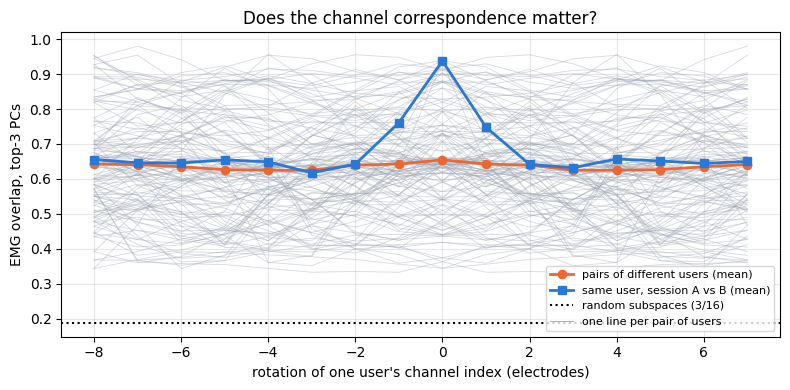

pairs of users whose best alignment is offset 0: 12%; within |offset| <= 1: 24% (random offset: 6% / 19%)
same user across sessions, best offset 0: 83%
cross-user overlap at offset 0: 0.655; at each pair's best offset (optimistic, max of 16): 0.751; same user other session: 0.938


In [9]:
k_rot = 3
rot_all = ov_emg[k_rot]["struct_all"]                       # (N, N, 15) offsets 1..15
curve_pairs = np.concatenate([ov_emg[k_rot]["full"][off][:, None], rot_all[off]], axis=1)   # offsets 0..15
curve_within = []
for u in USERS:
    Ua, Ub = basis["env", u, "A"][1], basis["env", u, "B"][1]
    curve_within.append([overlap(Ua, np.roll(Ub, s, axis=0), k_rot) for s in range(16)])
curve_within = np.array(curve_within)
signed = lambda c: np.concatenate([c[:, 8:], c[:, :8]], axis=1)  # reorder offsets to -8..7
offsets = np.arange(-8, 8)
fig, ax = plt.subplots(figsize=(8, 4))
for c in signed(curve_pairs):
    ax.plot(offsets, c, color=GREY, lw=0.6, alpha=0.4)
ax.plot(offsets, signed(curve_pairs).mean(0), "o-", color=ORANGE, lw=2, label="pairs of different users (mean)")
ax.plot(offsets, signed(curve_within).mean(0), "s-", color=BLUE, lw=2, label="same user, session A vs B (mean)")
ax.axhline(k_rot / D_EMG, ls=":", color="k", label=f"random subspaces ({k_rot}/16)")
ax.plot([], [], color=GREY, lw=0.6, label="one line per pair of users")
ax.set_xlabel("rotation of one user's channel index (electrodes)"); ax.set_ylabel(f"EMG overlap, top-{k_rot} PCs")
ax.set_title("Does the channel correspondence matter?"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
best = np.argmax(curve_pairs, axis=1)
best = np.where(best > 8, best - 16, best)
print(f"pairs of users whose best alignment is offset 0: {np.mean(best == 0):.0%}; within |offset| <= 1: "
      f"{np.mean(np.abs(best) <= 1):.0%} (random offset: {1 / 16:.0%} / {3 / 16:.0%})")
print(f"same user across sessions, best offset 0: {np.mean(np.argmax(curve_within, 1) == 0):.0%}")
print(f"cross-user overlap at offset 0: {curve_pairs[:, 0].mean():.3f}; at each pair's best offset (optimistic, max of 16): "
      f"{curve_pairs.max(1).mean():.3f}; same user other session: {curve_within[:, 0].mean():.3f}")

**What we see.** Within a person the band goes back to the same place: across sessions the overlap peaks at offset
0 for 83 % of users. Between people it does not: only 12 % of pairs peak at offset 0 (6 % expected by chance) and
24 % within ±1 electrode (19 % by chance). Even when each pair is allowed its best rotation (an optimistic, max-of-16
number) the cross-person overlap only reaches 0.75, well below the within-person 0.94. So people differ by more
than a band rotation: anatomy, band tightness and position along the forearm also matter. We cannot separate
these factors with this data.

**Leave-one-user-out for the EMG.** Same three bases as for the pose, plus the other-users basis with the held-out
user's channels rotated (mean over the 15 offsets), which says how much of the transfer survives a band rotation.
We report the fraction of variance explained (the EMG has no natural unit like degrees).

In [10]:
rec_emg = louo("env", rotate_null=True)
rec_emg["basis_grp"] = rec_emg.basis.where(~rec_emg.basis.str.startswith("other users, channels rotated"),
                                           "other users, channels rotated (mean of 15)")
ve_emg = rec_emg.pivot_table(index="k", columns="basis_grp", values="VE", aggfunc="mean")
print("EMG variance explained, mean over users:\n", ve_emg.round(3).to_string())

# fraction of the own-basis (other session) variance explained that the other-users basis achieves
def transfer_ratio(rec, col="basis"):
    piv = rec.pivot_table(index=["user", "k"], columns=col, values="VE")
    return (piv["other users"] / piv["own, other session"]).groupby("k").agg(["mean", "min"])


tr_pose, tr_emg = transfer_ratio(rec_pose), transfer_ratio(rec_emg, "basis_grp")
print("\nVE(other users) / VE(own, other session): pose\n", tr_pose.round(3).to_string())
print("EMG\n", tr_emg.round(3).to_string())

EMG variance explained, mean over users:
 basis_grp  none (mean only)  other users  other users, channels rotated (mean of 15)  own, in-sample  own, other session
k                                                                                                                       
2                       0.0        0.664                                       0.633           0.734               0.721
4                       0.0        0.814                                       0.779           0.882               0.871
6                       0.0        0.883                                       0.852           0.943               0.932
8                       0.0        0.925                                       0.896           0.971               0.964
12                      0.0        0.981                                       0.955           0.994               0.992

VE(other users) / VE(own, other session): pose
      mean    min
k               
2   0.983  0.955
4   0.978  

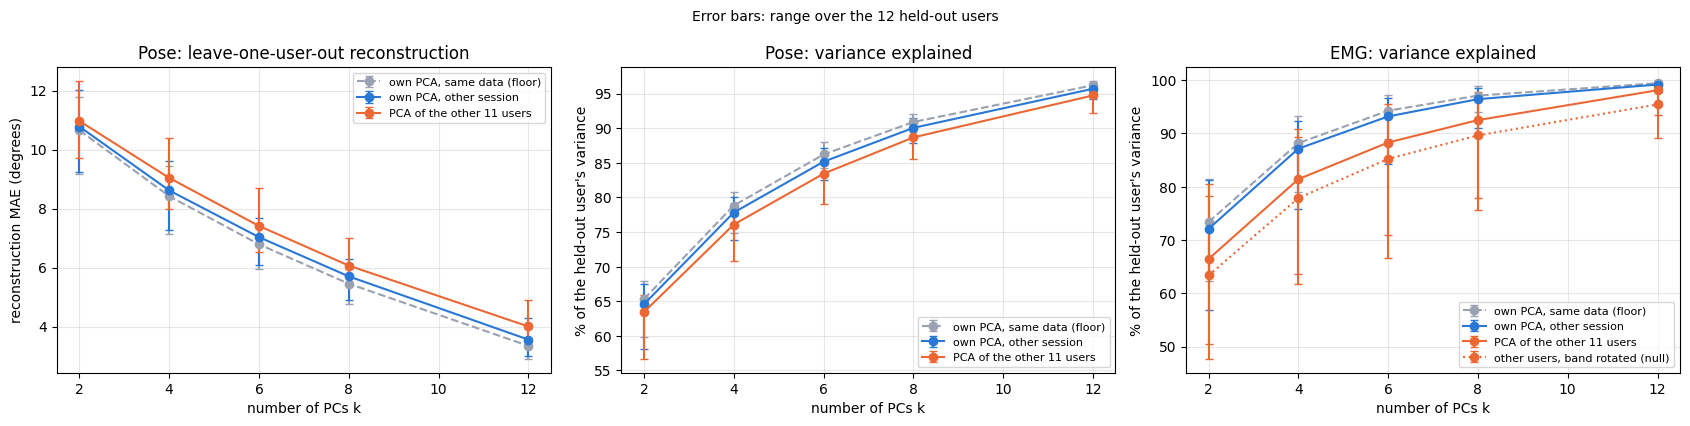

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
styles = {"own, in-sample": (GREY, "--", "own PCA, same data (floor)"),
          "own, other session": (BLUE, "-", "own PCA, other session"),
          "other users": (ORANGE, "-", "PCA of the other 11 users"),
          "other users, channels rotated (mean of 15)": (ORANGE, ":", "other users, band rotated (null)")}
for name, (col, ls, lab) in list(styles.items())[:3]:
    sub = rec_pose[rec_pose.basis == name].groupby("k").MAE
    axs[0].errorbar(KS_REC, sub.mean(), yerr=[sub.mean() - sub.min(), sub.max() - sub.mean()], color=col, ls=ls,
                    marker="o", capsize=3, label=lab)
axs[0].set_xlabel("number of PCs k"); axs[0].set_ylabel("reconstruction MAE (degrees)")
axs[0].set_title("Pose: leave-one-user-out reconstruction"); axs[0].legend(fontsize=8); axs[0].grid(alpha=0.3)
for ax, rec, col_name, title in [(axs[1], rec_pose, "basis", "Pose: variance explained"),
                                 (axs[2], rec_emg, "basis_grp", "EMG: variance explained")]:
    for name, (col, ls, lab) in styles.items():
        sub = rec[rec[col_name] == name].groupby(["k", "user"]).VE.mean().groupby("k")
        if sub.ngroups == 0:
            continue
        ax.errorbar(KS_REC, 100 * sub.mean(), yerr=[100 * (sub.mean() - sub.min()), 100 * (sub.max() - sub.mean())],
                    color=col, ls=ls, marker="o", capsize=3, label=lab)
    ax.set_xlabel("number of PCs k"); ax.set_ylabel("% of the held-out user's variance"); ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
fig.suptitle("Error bars: range over the 12 held-out users", fontsize=10)
plt.tight_layout()
if EXPORT_DIR:
    fig.savefig(Path(EXPORT_DIR) / "figs" / "cross_user_louo.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** The other-users basis explains 81 % of a new person's EMG variance at k = 4, against 87 % for the
person's own basis from another session (ratio 0.93; worst user 0.76, while the worst user for the pose was 0.96).
Rotating the held-out person's channels at random costs only 3.5 points (78 %): most of what transfers is the generic
global-effort component, not channel-specific structure. The EMG transfer is clearly worse and much more variable
across people than the pose transfer (compare the error bars of the middle and right panels).

## 3. The key comparison: is pose structure more shared than EMG structure?

Raw overlaps cannot be compared directly: the pose lives in 20 dimensions and the EMG in 16 (different chance
levels), and each signal has its own generic structure (a global PC1, smoothness). Two normalised statistics:

- **chance-normalised overlap** (o − k/D) / (1 − k/D): 0 = random subspaces, 1 = identical;
- **sharedness index** (cross-user − null) / (within-user − null): the fraction of each person's *reliable,
  non-generic* structure that other people share. Ceiling = the same person's other session; both terms computed on
  session halves so that the amount of data matches. Two floors:
  - *shuffle null* (joints / channels randomly permuted): removes chance alignment only;
  - *structured null* (fingers swapped for the pose, band rotated for the EMG): also removes the generic structure
    that any person would share, so only the **specific correspondence** (this joint ↔ this joint, this electrode ↔
    this electrode) counts. This is the fairest pose-vs-EMG comparison.

Uncertainty: bootstrap over users (resample the 12 users with replacement, drop self-pairs; 2000 resamples), and an
exact sign-flip permutation test on the per-user paired differences (pose minus EMG, chance-normalised overlap).

In [12]:
def chance_norm(o, k, D):
    return (o - k / D) / (1 - k / D)


def sharedness(s, users_idx, null_key="shuffle"):
    idx = np.asarray(users_idx)
    mask = idx[:, None] != idx[None, :]
    cross = s["half"][np.ix_(idx, idx)][mask].mean()
    within = s["within_session"][idx].mean()
    null = s[null_key][np.ix_(idx, idx)][mask].mean()
    return (cross - null) / (within - null)


def cross_norm(s, users_idx, k, D):
    idx = np.asarray(users_idx)
    mask = idx[:, None] != idx[None, :]
    return chance_norm(s["full"][np.ix_(idx, idx)][mask].mean(), k, D)


def all_stats(sp, se, idx, k):
    return {"pose chance-norm": cross_norm(sp, idx, k, D_POSE), "EMG chance-norm": cross_norm(se, idx, k, D_EMG),
            "pose sharedness (shuffle null)": sharedness(sp, idx), "EMG sharedness (shuffle null)": sharedness(se, idx),
            "pose sharedness (finger-perm. null)": sharedness(sp, idx, "struct"),
            "EMG sharedness (rotation null)": sharedness(se, idx, "struct")}


N_BOOT = 2000
flips = np.array([[1 if (m >> j) & 1 else -1 for j in range(N)] for m in range(2 ** N)])
boot_rows, stats = [], {}
for k in KS:
    sp, se = ov_pose[k], ov_emg[k]
    point = all_stats(sp, se, np.arange(N), k)
    boots = []
    for _ in range(N_BOOT):
        idx = rng.integers(0, N, N)
        if len(set(idx)) >= 3:
            boots.append(all_stats(sp, se, idx, k))
    boots = pd.DataFrame(boots)
    for b in (boots, point):
        b["diff chance-norm"] = b["pose chance-norm"] - b["EMG chance-norm"]
        b["diff sharedness (shuffle nulls)"] = b["pose sharedness (shuffle null)"] - b["EMG sharedness (shuffle null)"]
        b["diff sharedness (structured nulls)"] = b["pose sharedness (finger-perm. null)"] - b["EMG sharedness (rotation null)"]
    # exact sign-flip test on per-user paired differences of the chance-normalised overlap
    per_user_pose = np.array([chance_norm(sp["full"][i][off[i]].mean(), k, D_POSE) for i in range(N)])
    per_user_emg = np.array([chance_norm(se["full"][i][off[i]].mean(), k, D_EMG) for i in range(N)])
    d = per_user_pose - per_user_emg
    p_perm = np.mean(np.abs(flips @ d) >= np.abs(d.sum()) - 1e-12)
    stats[k] = {"point": point, "ci": boots.quantile([0.025, 0.975]).to_dict(), "p_signflip": p_perm,
                "p_boot_diff_structured_le0": float(np.mean(boots["diff sharedness (structured nulls)"] <= 0)),
                "per_user_pose": per_user_pose, "per_user_emg": per_user_emg}
    for name, v in point.items():
        lo, hi = boots[name].quantile([0.025, 0.975])
        boot_rows.append({"k": k, "statistic": name, "value": v, "95% CI low": lo, "95% CI high": hi})
boot_tab = pd.DataFrame(boot_rows).set_index(["k", "statistic"])
print(boot_tab.round(3).to_string())
for k in KS:
    print(f"k={k}: sign-flip test on per-user (pose - EMG) chance-normalised overlap: p = {stats[k]['p_signflip']:.4f}; "
          f"users with pose > EMG: {np.sum(stats[k]['per_user_pose'] > stats[k]['per_user_emg'])}/{N}; "
          f"bootstrap P(structured diff <= 0) = {stats[k]['p_boot_diff_structured_le0']:.4f}")

                                       value  95% CI low  95% CI high
k statistic                                                          
3 pose chance-norm                     0.768       0.706        0.834
  EMG chance-norm                      0.575       0.455        0.693
  pose sharedness (shuffle null)       0.792       0.736        0.850
  EMG sharedness (shuffle null)        0.460       0.281        0.645
  pose sharedness (finger-perm. null)  0.467       0.338        0.606
  EMG sharedness (rotation null)       0.073      -0.042        0.204
  diff chance-norm                     0.193       0.053        0.342
  diff sharedness (shuffle nulls)      0.332       0.137        0.527
  diff sharedness (structured nulls)   0.394       0.175        0.591
5 pose chance-norm                     0.724       0.694        0.759
  EMG chance-norm                      0.648       0.522        0.771
  pose sharedness (shuffle null)       0.781       0.734        0.833
  EMG sharedness (sh

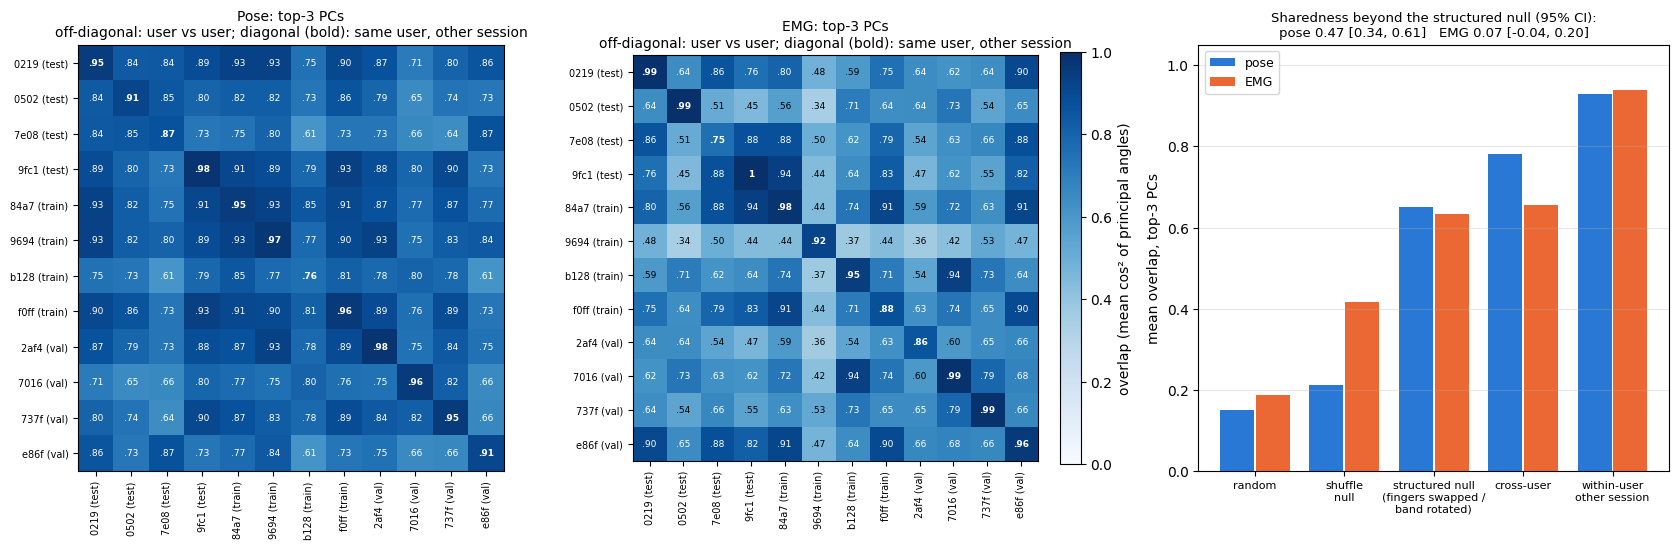

In [13]:
K_SHOW = 3
fig = plt.figure(figsize=(17, 5.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.05])
for j, (key, s, D, title) in enumerate([("ang", ov_pose[K_SHOW], D_POSE, f"Pose: top-{K_SHOW} PCs"),
                                        ("env", ov_emg[K_SHOW], D_EMG, f"EMG: top-{K_SHOW} PCs")]):
    ax = fig.add_subplot(gs[j])
    M = s["full"].copy()
    np.fill_diagonal(M, s["within_session"])
    im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for a in range(N):
        for b in range(N):
            ax.text(b, a, "1" if f"{M[a, b]:.2f}" == "1.00" else f"{M[a, b]:.2f}"[1:], ha="center", va="center", fontsize=6.5,
                    color="white" if M[a, b] > 0.6 else "black", fontweight="bold" if a == b else "normal")
    ax.set_xticks(range(N), [LABEL[u] for u in USERS], rotation=90, fontsize=7)
    ax.set_yticks(range(N), [LABEL[u] for u in USERS], fontsize=7)
    ax.set_title(f"{title}\noff-diagonal: user vs user; diagonal (bold): same user, other session", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.046, label="overlap (mean cos² of principal angles)")
ax = fig.add_subplot(gs[2])
levels = [("random", lambda s: s["random"]), ("shuffle\nnull", lambda s: np.nanmean(s["shuffle"])),
          ("structured null\n(fingers swapped /\nband rotated)", lambda s: s["struct"][off].mean()),
          ("cross-user", lambda s: s["half"][off].mean()),
          ("within-user\nother session", lambda s: s["within_session"].mean())]
x = np.arange(len(levels))
for off_x, (s, col, lab) in [(-0.2, (ov_pose[K_SHOW], BLUE, "pose")), (0.2, (ov_emg[K_SHOW], ORANGE, "EMG"))]:
    ax.bar(x + off_x, [f(s) for _, f in levels], width=0.38, color=col, label=lab)
ax.set_xticks(x, [l for l, _ in levels], fontsize=8)
ax.set_ylabel(f"mean overlap, top-{K_SHOW} PCs"); ax.set_ylim(0, 1.05); ax.legend(fontsize=9, loc="upper left")
pt, ci = stats[K_SHOW]["point"], stats[K_SHOW]["ci"]
fmt = lambda n: f"{pt[n]:.2f} [{ci[n][0.025]:.2f}, {ci[n][0.975]:.2f}]"
ax.set_title("Sharedness beyond the structured null (95% CI):\n"
             f"pose {fmt('pose sharedness (finger-perm. null)')}   EMG {fmt('EMG sharedness (rotation null)')}", fontsize=9.5)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
if EXPORT_DIR:
    fig.savefig(Path(EXPORT_DIR) / "figs" / "cross_user_overlap.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see (k = 3).**

- Chance-normalised cross-person overlap: pose 0.77 [0.71, 0.83] vs EMG 0.58 [0.46, 0.69]. Pose is higher for
  **12 of 12 users** (sign-flip p = 0.0005). At k = 5 the gap is smaller (0.72 vs 0.65, 9/12 users, p = 0.03; the
  bootstrap CI of the difference includes 0); at k = 8 it is 0.70 vs 0.57 (12/12, p = 0.0005).
- Sharedness with the shuffle null: pose 0.79 [0.74, 0.85] vs EMG 0.46 [0.28, 0.65].
- **Sharedness with the structured nulls** (the fairest comparison): pose 0.47 [0.34, 0.61] vs EMG 0.07
  [-0.04, 0.20]; difference 0.39 [0.18, 0.59]. At k = 5: 0.54 vs 0.16 (difference 0.38 [0.18, 0.58]); at k = 8:
  0.58 vs 0.26 (difference 0.33 [0.11, 0.53]).

About half of a person's reliable, finger-specific pose structure is shared with other people, while almost none
of the electrode-specific EMG structure is (beyond what any band rotation would give). The overlap matrices show it
directly: the pose matrix is uniformly dark, while the EMG matrix is a patchwork, with a few pairs as similar as two
sessions of one person (e.g. 0.94 for b128-7016) and others near the rotation floor (user 9694 overlaps nobody,
0.34-0.53).

### 3b. Who vs what: does the subspace follow the person or the task?

In section 1 the time split (first vs second half of each recording) gave a *lower* pose overlap than the session
split, while for the EMG it gave a higher one. The two halves of a recording contain different gestures, so this
hints that the pose subspace follows **what** is done, and the EMG subspace follows **who** does it (and where the
band is). A 2 × 2 design tests it directly: split the 13 stages at random into two groups of 6 and 7, fit PCA on one
session half × one stage group (a quarter of each person's data), and compare bases that share or differ in person
and in task group. Every comparison crosses sessions (half A vs half B), so the band was always put on again.
20 random stage splits, k = 3. Person effect = mean(same person) − mean(other person); task effect = mean(same
tasks) − mean(other tasks); 95% CI from a bootstrap over users.

cond  same person\nsame tasks  same person\nother tasks  other person\nsame tasks  other person\nother tasks
key                                                                                                         
pose                    0.902                     0.670                     0.756                      0.628
EMG                     0.922                     0.896                     0.660                      0.659

                      value  95% CI low  95% CI high
signal effect                                       
pose   person effect  0.094       0.081        0.107
       task effect    0.180       0.167        0.193
EMG    person effect  0.250       0.202        0.302
       task effect    0.013       0.007        0.021


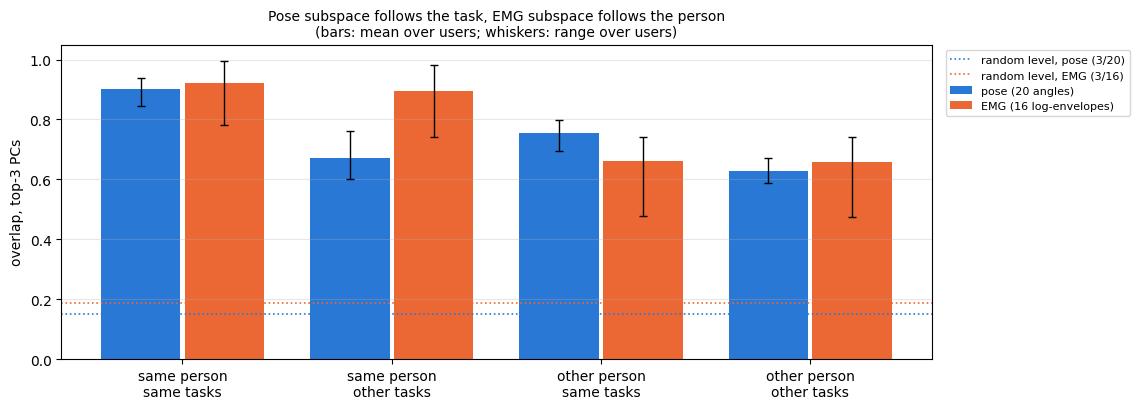

In [14]:
STAGE_LIST = sorted(info.stage.unique())
N_SPLITS, K22 = 20, 3
CONDS = ["same person\nsame tasks", "same person\nother tasks", "other person\nsame tasks", "other person\nother tasks"]
rows22 = []
for sp_i in range(N_SPLITS):
    perm = rng.permutation(STAGE_LIST)
    groups = [set(perm[:6]), set(perm[6:])]
    for key in ["ang", "env"]:
        Bs = {(u, h, g): pca(data(u, key, half=h, stages=groups[g]))[1] for u in USERS for h in "AB" for g in (0, 1)}
        for g in (0, 1):
            for a in USERS:
                rows22.append((key, CONDS[0], a, overlap(Bs[a, "A", g], Bs[a, "B", g], K22)))
                rows22.append((key, CONDS[1], a, overlap(Bs[a, "A", g], Bs[a, "B", 1 - g], K22)))
                for b in USERS:
                    if b != a:
                        rows22.append((key, CONDS[2], a, overlap(Bs[a, "A", g], Bs[b, "B", g], K22)))
                        rows22.append((key, CONDS[3], a, overlap(Bs[a, "A", g], Bs[b, "B", 1 - g], K22)))
df22 = pd.DataFrame(rows22, columns=["key", "cond", "user", "overlap"])
per_user22 = df22.groupby(["key", "cond", "user"]).overlap.mean().unstack("cond")[CONDS]


def effects(tab):
    m = tab.mean()
    return {"person effect": (m[CONDS[0]] + m[CONDS[1]] - m[CONDS[2]] - m[CONDS[3]]) / 2,
            "task effect": (m[CONDS[0]] + m[CONDS[2]] - m[CONDS[1]] - m[CONDS[3]]) / 2}


eff_rows = []
for key, name in [("ang", "pose"), ("env", "EMG")]:
    tab = per_user22.loc[key]
    pt22 = effects(tab)
    boots22 = pd.DataFrame([effects(tab.iloc[rng.integers(0, N, N)]) for _ in range(N_BOOT)])
    for eff, v in pt22.items():
        eff_rows.append({"signal": name, "effect": eff, "value": v, "95% CI low": boots22[eff].quantile(0.025),
                         "95% CI high": boots22[eff].quantile(0.975)})
eff_tab = pd.DataFrame(eff_rows).set_index(["signal", "effect"])
print(per_user22.groupby(level="key").mean().rename(index={"ang": "pose", "env": "EMG"}).round(3).to_string())
print()
print(eff_tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(11.5, 4.2))
x = np.arange(4)
for off_x, key, col, lab in [(-0.2, "ang", BLUE, "pose (20 angles)"), (0.2, "env", ORANGE, "EMG (16 log-envelopes)")]:
    tab = per_user22.loc[key]
    ax.bar(x + off_x, tab.mean(), width=0.38, color=col, label=lab)
    ax.errorbar(x + off_x, tab.mean(), yerr=[tab.mean() - tab.min(), tab.max() - tab.mean()], fmt="none",
                ecolor="k", capsize=3, lw=1)
ax.axhline(K22 / D_POSE, color=BLUE, ls=":", lw=1.2, label="random level, pose (3/20)")
ax.axhline(K22 / D_EMG, color=ORANGE, ls=":", lw=1.2, label="random level, EMG (3/16)")
ax.set_xticks(x, CONDS); ax.set_ylabel(f"overlap, top-{K22} PCs"); ax.set_ylim(0, 1.05)
ax.set_title("Pose subspace follows the task, EMG subspace follows the person\n(bars: mean over users; whiskers: range over users)",
             fontsize=10)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
if EXPORT_DIR:
    fig.savefig(Path(EXPORT_DIR) / "figs" / "cross_user_who_vs_what.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** A clean dissociation:

| top-3 overlap | same person, same tasks | same person, other tasks | other person, same tasks | other person, other tasks |
|---|---|---|---|---|
| pose | 0.90 | 0.67 | 0.76 | 0.63 |
| EMG | 0.92 | 0.90 | 0.66 | 0.66 |

- **Pose**: changing the tasks costs more (task effect 0.18 [0.17, 0.19]) than changing the person (person effect
  0.09 [0.08, 0.11]). Two people doing the same gestures have more similar pose subspaces than one person doing
  different gestures.
- **EMG**: changing the person costs a lot (0.25 [0.20, 0.30]) and changing the tasks almost nothing (0.01
  [0.01, 0.02]). The EMG subspace is a fingerprint of the person and the band position, whatever the hand does.

This sharpens the claim of section 3. The shared pose structure is largely *task-driven*: people share the pose
subspace **because they were asked to make the same gestures** (and because hands share mechanics), and the
remaining person effect is small. That is what a "shared vocabulary under shared instructions" predicts, but it
is not evidence that the vocabulary is *neural* in origin.

## 4. Does every person decode the same pose directions? (reduced-rank regression per user)

`neural_synergies.ipynb` found, for one person, that a linear EMG → pose map needs only rank ~3 and that its
output directions coincide with the top pose PCs. If that is a general property, every person should need a
similar small rank, and each person's **decodable pose subspace** should coincide with the pooled pose PCs (and
with the other people's decodable subspaces), even though their EMG inputs differ.

Per user: features = 16 log-envelopes × lags {0, 2, 5, 10, 15} samples (0-300 ms of history), standardised; target
= 20 angles (degrees); ridge (λ = 10) then rank-r projection onto the top-r directions of the fitted values;
blocked 5-fold CV within recordings (each recording cut into 5 consecutive blocks); R² pooled over the 20 angles.

In [15]:
def lagged(X, lags=LAGS):
    return np.hstack([X if l == 0 else np.vstack([np.repeat(X[:1], l, axis=0), X[:-l]]) for l in lags])


RANKS = list(range(1, 13))


def rrr_user(u, lam=10.0):
    Xs, Ys, Fs = [], [], []
    for r in recs:
        if r["user"] != u:
            continue
        keep, T = r["ok"], len(r["ok"])
        Xs.append(lagged(r["env"].astype(np.float64))[keep]); Ys.append(r["ang"][keep].astype(np.float64))
        Fs.append((np.arange(T) * 5 // T)[keep])
    X, Y, folds = np.vstack(Xs), np.vstack(Ys), np.concatenate(Fs)
    preds = {rk: np.zeros_like(Y) for rk in RANKS}
    full = np.zeros_like(Y)
    for f in range(5):
        tr, te = folds != f, folds == f
        mx, sx, my = X[tr].mean(0), X[tr].std(0) + 1e-9, Y[tr].mean(0)
        A, B = (X[tr] - mx) / sx, (X[te] - mx) / sx
        W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y[tr] - my))
        full[te] = B @ W + my
        Vt = np.linalg.svd(A @ W, full_matrices=False)[2]
        for rk in RANKS:
            preds[rk][te] = B @ W @ Vt[:rk].T @ Vt[:rk] + my
    sst = ((Y - Y.mean(0)) ** 2).sum()
    r2 = {rk: 1 - ((Y - preds[rk]) ** 2).sum() / sst for rk in RANKS}
    r2_full = 1 - ((Y - full) ** 2).sum() / sst
    # decodable subspace from a fit on all of this user's data
    mx, sx, my = X.mean(0), X.std(0) + 1e-9, Y.mean(0)
    A = (X - mx) / sx
    W = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ (Y - my))
    V_rrr = np.linalg.svd(A @ W, full_matrices=False)[2].T          # (20, 20) pose-space directions
    return r2, r2_full, V_rrr


rrr = {u: rrr_user(u) for u in USERS}
U_pooled = np.linalg.eigh(np.mean([norm_cov(data(u, "ang")) for u in USERS], axis=0))[1][:, ::-1]
rows = []
for u in USERS:
    r2, r2_full, V = rrr[u]
    rank90 = next((rk for rk in RANKS if r2[rk] >= 0.9 * r2_full), np.nan)
    row = {"user": LABEL[u], "full-rank R²": r2_full, "rank for 90 %": rank90}
    for rk in (3, 5):
        row[f"r={rk}: vs pooled pose PCs"] = overlap(V, U_pooled, rk)
        row[f"r={rk}: vs own pose PCs"] = overlap(V, basis["ang", u, "all"][1], rk)
    rows.append(row)
tab_rrr = pd.DataFrame(rows).set_index("user")
print(tab_rrr.round(3).to_string())
print(f"\nrandom-subspace baseline: r=3 -> {3 / 20:.2f}, r=5 -> {5 / 20:.2f}")
rrr_cross = {rk: np.array([[overlap(rrr[a][2], rrr[b][2], rk) for b in USERS] for a in USERS]) for rk in (3, 5)}
for rk in (3, 5):
    print(f"r={rk}: decodable subspace, user vs user overlap: mean {rrr_cross[rk][off].mean():.3f} "
          f"(pose PCs user vs user: {ov_pose[rk]['full'][off].mean() if rk in ov_pose else np.nan:.3f})")

              full-rank R²  rank for 90 %  r=3: vs pooled pose PCs  r=3: vs own pose PCs  r=5: vs pooled pose PCs  r=5: vs own pose PCs
user                                                                                                                                   
0219 (test)          0.199              4                    0.872                 0.919                    0.694                 0.768
0502 (test)          0.219              4                    0.730                 0.644                    0.745                 0.839
7e08 (test)          0.193              3                    0.614                 0.660                    0.636                 0.706
9fc1 (test)          0.294              2                    0.693                 0.771                    0.637                 0.688
84a7 (train)         0.247              3                    0.630                 0.655                    0.678                 0.756
9694 (train)         0.200              3       

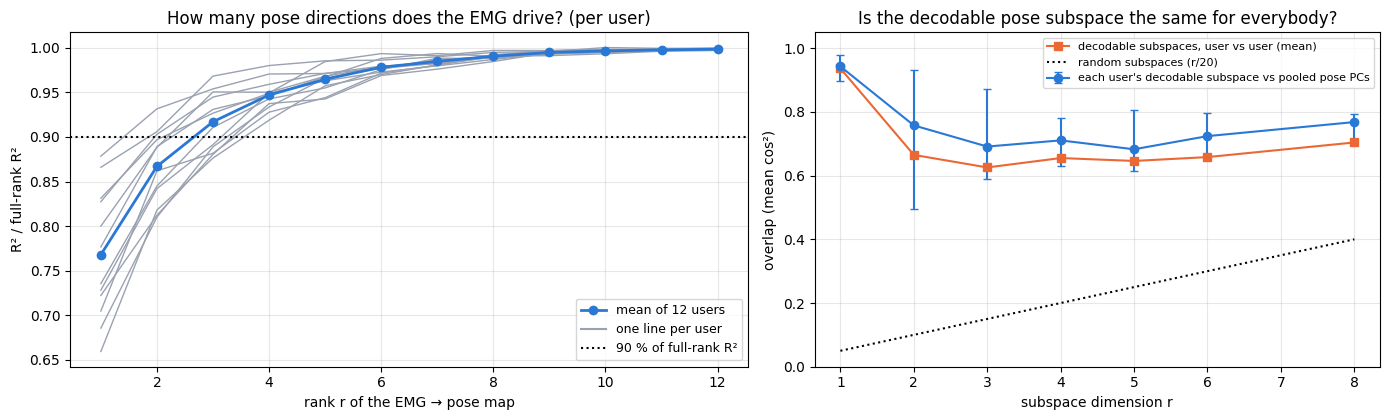

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.2, 1]})
for u in USERS:
    r2, r2_full, _ = rrr[u]
    axs[0].plot(RANKS, [r2[rk] / r2_full for rk in RANKS], color=GREY, lw=1)
mean_rel = np.mean([[rrr[u][0][rk] / rrr[u][1] for rk in RANKS] for u in USERS], axis=0)
axs[0].plot(RANKS, mean_rel, "o-", color=BLUE, lw=2, label="mean of 12 users")
axs[0].plot([], [], color=GREY, label="one line per user")
axs[0].axhline(0.9, ls=":", color="k", label="90 % of full-rank R²")
axs[0].set_xlabel("rank r of the EMG → pose map"); axs[0].set_ylabel("R² / full-rank R²")
axs[0].set_title("How many pose directions does the EMG drive? (per user)"); axs[0].legend(fontsize=9); axs[0].grid(alpha=0.3)
rk_list = [1, 2, 3, 4, 5, 6, 8]
vs_pooled = np.array([[overlap(rrr[u][2], U_pooled, rk) for rk in rk_list] for u in USERS])
vs_cross = np.array([rrr_cross_k[off].mean() for rrr_cross_k in
                     [np.array([[overlap(rrr[a][2], rrr[b][2], rk) for b in USERS] for a in USERS]) for rk in rk_list]])
axs[1].errorbar(rk_list, vs_pooled.mean(0), yerr=[vs_pooled.mean(0) - vs_pooled.min(0), vs_pooled.max(0) - vs_pooled.mean(0)],
                color=BLUE, marker="o", capsize=3, label="each user's decodable subspace vs pooled pose PCs")
axs[1].plot(rk_list, vs_cross, "s-", color=ORANGE, label="decodable subspaces, user vs user (mean)")
axs[1].plot(rk_list, [rk / 20 for rk in rk_list], ":", color="k", label="random subspaces (r/20)")
axs[1].set_xlabel("subspace dimension r"); axs[1].set_ylabel("overlap (mean cos²)"); axs[1].set_ylim(0, 1.05)
axs[1].set_title("Is the decodable pose subspace the same for everybody?"); axs[1].legend(fontsize=8); axs[1].grid(alpha=0.3)
plt.tight_layout()
if EXPORT_DIR:
    fig.savefig(Path(EXPORT_DIR) / "figs" / "cross_user_rrr.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.**

- The linear EMG → pose decoder is weak in absolute terms (full-rank R² 0.10-0.32 per user, pooled over 20
  angles), but in every person it is **low-rank**: rank 2-4 (median 3) reaches 90 % of the full-rank R².
- Each person's decodable 3-D pose subspace overlaps 0.69 on average (0.59-0.87) with the pooled pose PCs (random:
  0.15); 0.68 at r = 5 (random 0.25). So in everybody the EMG mainly drives the top postural synergies, as found for
  the single user of `neural_synergies.ipynb`.
- The decodable subspaces of two people overlap 0.63 (r = 3), less than their pose PCs (0.80). Part of this is
  estimation noise (low R²), part may be real: different people may have different "readable" directions,
  depending on which muscles their band covers.

## 5. Robustness checks

The headline comparison (k = 3) recomputed with different choices:

- **one hand only** (left / right), instead of pooling both hands;
- **EMG z-scored per channel** (PCA of the correlation matrix instead of the covariance of log-envelopes). Warning
  in advance: for a ring of electrodes whose correlation decays smoothly with distance, the eigenvectors of the
  correlation matrix are close to Fourier modes around the wrist (constant, cos, sin, ...), and that subspace is
  **the same for any rotation of the band**. So this variant should be read against its rotation null;
- **left vs right hand of the same person** as an extra reference: if pooling both hands were wrong (e.g. mirrored
  electrode order or joint sign conventions), this overlap would be low.

In [17]:
def overlaps_from_bases(B, D, k, struct_perms, n_shuffle=100):
    """B: dict user -> dict with 'all', 'A', 'B' eigenvector matrices. Returns the stats needed by sharedness()."""
    full = np.array([[overlap(B[a]["all"], B[b]["all"], k) for b in USERS] for a in USERS])
    half = np.array([[np.mean([overlap(B[a][ha], B[b][hb], k) for ha in "AB" for hb in "AB"]) for b in USERS] for a in USERS])
    within = np.array([overlap(B[u]["A"], B[u]["B"], k) for u in USERS])
    shuffle = np.array([[np.mean([overlap(B[a]["all"], B[b]["all"][rng.permutation(D)], k) for _ in range(n_shuffle)])
                         if a != b else np.nan for b in USERS] for a in USERS])
    struct = np.array([[np.mean([overlap(B[a]["all"], B[b]["all"][p], k) for p in struct_perms]) for b in USERS] for a in USERS])
    return {"full": full, "half": half, "within_session": within, "shuffle": shuffle, "struct": struct, "random": k / D}


def side_bases(key, side):
    return {u: {"all": pca(data(u, key, side=side))[1], "A": pca(data(u, key, half="A", side=side))[1],
                "B": pca(data(u, key, half="B", side=side))[1]} for u in USERS}


def zpca(X):
    return pca((X - X.mean(0)) / X.std(0))[1]


rob = []
k = 3
for label, Bp, Be in [("both hands (main)", None, None),
                      ("left hand only", side_bases("ang", "left"), side_bases("env", "left")),
                      ("right hand only", side_bases("ang", "right"), side_bases("env", "right")),
                      ("EMG z-scored per channel", None,
                       {u: {"all": zpca(data(u, "env")), "A": zpca(data(u, "env", half="A")),
                            "B": zpca(data(u, "env", half="B"))} for u in USERS})]:
    sp = ov_pose[k] if Bp is None else overlaps_from_bases(Bp, D_POSE, k, FINGER_PERMS)
    se = ov_emg[k] if Be is None else overlaps_from_bases(Be, D_EMG, k, ROTATIONS)
    rob.append({"variant": label, "pose cross-user": sp["half"][off].mean(), "pose within-user": sp["within_session"].mean(),
                "pose finger-perm. null": sp["struct"][off].mean(),
                "pose sharedness (shuffle)": sharedness(sp, range(N)),
                "pose sharedness (structured)": sharedness(sp, range(N), "struct"),
                "EMG cross-user": se["half"][off].mean(), "EMG within-user": se["within_session"].mean(),
                "EMG rotation null": se["struct"][off].mean(),
                "EMG sharedness (shuffle)": sharedness(se, range(N)),
                "EMG sharedness (structured)": sharedness(se, range(N), "struct")})
tab_rob = pd.DataFrame(rob).set_index("variant")
print(tab_rob.round(3).T.to_string())
lr = {key: np.array([overlap(basis[key, u, "left"][1], basis[key, u, "right"][1], k) for u in USERS]) for key in ["ang", "env"]}
print(f"\nleft vs right hand, same user, k={k}: pose {lr['ang'].mean():.3f} (min {lr['ang'].min():.3f}), "
      f"EMG {lr['env'].mean():.3f} (min {lr['env'].min():.3f})")

variant                       both hands (main)  left hand only  right hand only  EMG z-scored per channel
pose cross-user                           0.781           0.767            0.748                     0.781
pose within-user                          0.930           0.916            0.895                     0.930
pose finger-perm. null                    0.650           0.633            0.627                     0.650
pose sharedness (shuffle)                 0.792           0.789            0.785                     0.792
pose sharedness (structured)              0.467           0.473            0.452                     0.467
EMG cross-user                            0.656           0.662            0.721                     0.800
EMG within-user                           0.938           0.895            0.928                     0.930
EMG rotation null                         0.634           0.613            0.686                     0.785
EMG sharedness (shuffle)             

**What we see.**

- **One hand at a time**: same picture. Pose sharedness beyond the finger-permutation null 0.47 (left) and 0.45
  (right); EMG beyond the rotation null 0.17 and 0.15.
- **Z-scored EMG** is the trap made visible: cross-person overlap jumps to 0.80 (as high as the pose) and the
  shuffle-null sharedness to 0.75. But the rotation null jumps too (0.785), so the sharedness beyond it is 0.10.
  With z-scored channels the top PCs become smooth patterns around the wrist (constant, cos, sin) that any band
  position produces. Without the rotation null we would have wrongly concluded that EMG structure is as shared as
  pose structure.
- **Left vs right hand of the same person**: pose 0.87 (min 0.65), EMG 0.74 (min 0.62; the rotation null is
  ~0.63). The two hands of one person are less alike in EMG than two sessions of the same hand (0.90-0.93), so
  pooling hands mixes two related but not identical EMG subspaces. That is why the per-hand checks above matter;
  they do not change the conclusion.

## 6. Summary

In [18]:
summary_rows = [
    ("participation ratio (mean ± SD over users)", f"{spec_pose.PR.mean():.2f} ± {spec_pose.PR.std():.2f}",
     f"{spec_emg.PR.mean():.2f} ± {spec_emg.PR.std():.2f}"),
    ("PCs for 90 % variance (range over users)", f"{spec_pose['k for 90 %'].min()}-{spec_pose['k for 90 %'].max()}",
     f"{spec_emg['k for 90 %'].min()}-{spec_emg['k for 90 %'].max()}"),
]
for kk in KS:
    summary_rows.append((f"top-{kk} overlap: cross-user / within-user / structured null / random",
                         f"{ov_pose[kk]['half'][off].mean():.2f} / {ov_pose[kk]['within_session'].mean():.2f} / "
                         f"{ov_pose[kk]['struct'][off].mean():.2f} / {kk / 20:.2f}",
                         f"{ov_emg[kk]['half'][off].mean():.2f} / {ov_emg[kk]['within_session'].mean():.2f} / "
                         f"{ov_emg[kk]['struct'][off].mean():.2f} / {kk / 16:.2f}"))
for kk in KS:
    p, ci = stats[kk]["point"], stats[kk]["ci"]
    f_ = lambda n: f"{p[n]:.2f} [{ci[n][0.025]:.2f}, {ci[n][0.975]:.2f}]"
    summary_rows.append((f"sharedness, k={kk}, shuffle null [95% CI]", f_("pose sharedness (shuffle null)"),
                         f_("EMG sharedness (shuffle null)")))
    summary_rows.append((f"sharedness, k={kk}, structured null [95% CI]", f_("pose sharedness (finger-perm. null)"),
                         f_("EMG sharedness (rotation null)")))
summary_rows.append(("who vs what (k=3): person effect / task effect",
                     f"{eff_tab.loc[('pose', 'person effect'), 'value']:.2f} / {eff_tab.loc[('pose', 'task effect'), 'value']:.2f}",
                     f"{eff_tab.loc[('EMG', 'person effect'), 'value']:.2f} / {eff_tab.loc[('EMG', 'task effect'), 'value']:.2f}"))
summary_rows.append(("LOUO, k=4: VE other-users basis / own other-session basis",
                     f"{tr_pose.loc[4, 'mean']:.3f} (worst {tr_pose.loc[4, 'min']:.3f})",
                     f"{tr_emg.loc[4, 'mean']:.3f} (worst {tr_emg.loc[4, 'min']:.3f})"))
summary_rows.append(("LOUO, k=4: MAE other users vs own other session (deg)",
                     f"{mae_pose.loc[4, 'other users']:.2f} vs {mae_pose.loc[4, 'own, other session']:.2f}", "-"))
summary_rows.append(("RRR full-rank R² (range); rank for 90 % of it (median, range)",
                     f"{tab_rrr['full-rank R²'].min():.2f}-{tab_rrr['full-rank R²'].max():.2f}; "
                     f"{tab_rrr['rank for 90 %'].median():.0f} ({tab_rrr['rank for 90 %'].min():.0f}-{tab_rrr['rank for 90 %'].max():.0f})", "-"))
summary_rows.append(("decodable subspace (r=3): vs pooled pose PCs; user vs user",
                     f"{tab_rrr['r=3: vs pooled pose PCs'].mean():.2f}; {rrr_cross[3][off].mean():.2f} (random 0.15)", "-"))
final = pd.DataFrame(summary_rows, columns=["measure", "pose (20 angles)", "EMG (16 log-envelopes)"]).set_index("measure")
pd.set_option("display.max_colwidth", 120)
final

,pose (20 angles),EMG (16 log-envelopes)
measure,,
participation ratio (mean ± SD over users),3.28 ± 0.29,2.88 ± 0.72
PCs for 90 % variance (range over users),8-9,4-7
top-3 overlap: cross-user / within-user / structured null / random,0.78 / 0.93 / 0.65 / 0.15,0.66 / 0.94 / 0.63 / 0.19
top-5 overlap: cross-user / within-user / structured null / random,0.78 / 0.92 / 0.61 / 0.25,0.75 / 0.93 / 0.72 / 0.31
top-8 overlap: cross-user / within-user / structured null / random,0.82 / 0.93 / 0.65 / 0.40,0.79 / 0.93 / 0.74 / 0.50
"sharedness, k=3, shuffle null [95% CI]","0.79 [0.74, 0.85]","0.46 [0.28, 0.64]"
"sharedness, k=3, structured null [95% CI]","0.47 [0.34, 0.61]","0.07 [-0.04, 0.20]"
"sharedness, k=5, shuffle null [95% CI]","0.78 [0.73, 0.83]","0.65 [0.48, 0.79]"
"sharedness, k=5, structured null [95% CI]","0.54 [0.47, 0.63]","0.16 [-0.00, 0.33]"


### Interpretation

**Hypothesis: "pose synergies are shared across people more than EMG patterns are."** Supported, with an
important qualification.

- **Pose**: the same dimensionality in everybody (PR ≈ 3.3, 8-9 PCs for 90 %), top subspaces overlapping 0.80 between
  people, and a population PCA basis that compresses a new person's pose almost as well as their own (≤ 0.5°
  extra error on average). About half of each person's finger-specific structure is shared beyond a
  finger-permutation null.
- **EMG**: cross-person overlap is no higher than what a random band rotation produces (sharedness ≈ 0.07 beyond
  the rotation null), people's bands are not aligned with each other (12 % of pairs best at offset 0), and the
  subspace is a stable fingerprint of the person (0.94 across sessions, almost independent of the task).
- **The qualification** (section 3b): the pose subspace follows *what* people do more than *who* does it. All 12
  people did the same 13 instructed gestures, so the shared pose structure is at least partly imposed by the task
  set and the shared mechanics of the hand. "Common control vocabulary" is a fair description at the level of
  behaviour; it is not evidence that the vocabulary is neural.

**For the project.** A pose latent (PCA, likely an autoencoder too) can be fitted once on many people and reused
for a new person. The EMG → latent map is the person-specific part: it needs per-user calibration, or an
architecture that is invariant to band rotation and robust to anatomy, which is what emg2pose's user-generalisation
split measures. Every person's EMG drives about 3 pose dimensions, mostly the top pose PCs, which supports a
k ≈ 4-8 bottleneck across people.

### Caveats

- **12 users, 13 structured stages** (no free-style, no `unconstrained`). Instructed gestures share structure by
  design; free behaviour could show more person-specific pose structure.
- **Anatomy vs placement**: the EMG person effect mixes forearm anatomy, band position along and around the
  forearm, tightness and skin contact. The rotation analysis removes one of these factors, not all.
- **Linear, second-order structure only**: PCA subspaces of covariance, top-k only. Nonlinear manifolds (as an
  autoencoder would learn) could be shared differently. Near-equal eigenvalues at the k boundary add noise to the
  overlaps.
- **One EMG feature** (log RMS envelope, 20-450 Hz, 50 ms). Other features (spectral, motor-unit level) might
  carry more person-invariant structure.
- **Pose labels are IK outputs** from motion capture with per-person hand models; part of the person effect in the
  pose could be calibration rather than behaviour.
- **The nulls are modelling choices.** The finger-permutation null for the pose is strict (it keeps the thumb and
  all within-finger structure); the rotation null for the EMG assumes a ring of evenly spaced electrodes.
- **The RRR decoder is weak** (R² ≤ 0.32), so the decodable-subspace estimates are noisy.
- **Uncertainty**: bootstrap over only 12 users; pairs of users are not independent. The CIs are approximate.

In [19]:
if EXPORT_DIR:
    def tolist(x):
        return np.round(np.asarray(x, dtype=float), 4).tolist()
    out = {
        "data": {"dataset_dir": str(DATA_DIR), "n_users": N, "n_recordings": len(recs),
                 "stages": STAGE_LIST, "user_order": USERS,
                 "users": {u: {c: (v if isinstance(v, str) else float(v)) for c, v in summary.loc[u].items()} for u in USERS}},
        "per_user": {u: {"pose_PR": float(spec_pose.loc[LABEL[u], "PR"]), "emg_PR": float(spec_emg.loc[LABEL[u], "PR"]),
                         "pose_k90": int(spec_pose.loc[LABEL[u], "k for 90 %"]), "emg_k90": int(spec_emg.loc[LABEL[u], "k for 90 %"]),
                         "pose_cumvar": tolist(np.cumsum(basis["ang", u, "all"][0]) / basis["ang", u, "all"][0].sum()),
                         "emg_cumvar": tolist(np.cumsum(basis["env", u, "all"][0]) / basis["env", u, "all"][0].sum()),
                         "rrr_full_R2": float(rrr[u][1]), "rrr_rank90": float(tab_rrr.loc[LABEL[u], "rank for 90 %"]),
                         "rrr_r2_by_rank": {int(rk): float(v) for rk, v in rrr[u][0].items()},
                         "rrr_r3_overlap_pooled_pose_pcs": float(tab_rrr.loc[LABEL[u], "r=3: vs pooled pose PCs"]),
                         "rrr_r5_overlap_pooled_pose_pcs": float(tab_rrr.loc[LABEL[u], "r=5: vs pooled pose PCs"])}
                     for u in USERS},
        "overlap": {name: {str(kk): {"full_matrix": tolist(s[kk]["full"]), "half_matched_matrix": tolist(s[kk]["half"]),
                                     "within_user_other_session": tolist(s[kk]["within_session"]),
                                     "within_user_time_split": tolist(s[kk]["within_time"]),
                                     "shuffle_null_mean": float(np.nanmean(s[kk]["shuffle"])),
                                     "structured_null_mean": float(s[kk]["struct"][off].mean()),
                                     "structured_null": null_name, "random": s[kk]["random"]} for kk in KS}
                    for name, s, null_name in [("pose", ov_pose, "finger permutation"), ("emg", ov_emg, "band rotation")]},
        "summary_stats": {str(kk): {"point": {n: float(v) for n, v in stats[kk]["point"].items()},
                                    "ci95": {n: [float(v[0.025]), float(v[0.975])] for n, v in stats[kk]["ci"].items()},
                                    "p_signflip_chance_norm": float(stats[kk]["p_signflip"]),
                                    "p_boot_diff_structured_le0": stats[kk]["p_boot_diff_structured_le0"]} for kk in KS},
        "who_vs_what_k3": {"mean_overlap": per_user22.groupby(level="key").mean().rename(index={"ang": "pose", "env": "emg"})
                           .rename(columns=lambda c: c.replace("\n", " ")).round(4).to_dict(orient="index"),
                           "effects": {f"{s_} {e_}": [round(float(v), 4) for v in r_] for (s_, e_), r_ in eff_tab.iterrows()}},
        "louo": {"pose_MAE_deg": mae_pose.round(3).to_dict(), "pose_VE": ve_pose.round(4).to_dict(),
                 "emg_VE": ve_emg.round(4).to_dict(),
                 "transfer_ratio_pose": tr_pose.round(4).to_dict(), "transfer_ratio_emg": tr_emg.round(4).to_dict()},
        "rrr": {"cross_user_overlap_r3": tolist(rrr_cross[3]), "cross_user_overlap_r5": tolist(rrr_cross[5])},
        "emg_band_alignment_k3": {"frac_pairs_best_offset0": float(np.mean(best == 0)),
                                  "mean_overlap_by_offset_pairs": tolist(curve_pairs.mean(0)),
                                  "mean_overlap_by_offset_within": tolist(curve_within.mean(0))},
        "robustness_k3": tab_rob.round(4).to_dict(orient="index"),
        "left_vs_right_k3": {"pose": tolist(lr["ang"]), "emg": tolist(lr["env"])},
    }
    json.dump(out, open(Path(EXPORT_DIR) / "cross_user.json", "w"), indent=1, default=str)
    print("saved", Path(EXPORT_DIR) / "cross_user.json")

saved /tmp/claude-1000/-home-rodri-projects-emg2poseneuromatch-semg2pose/1ade1be6-b4fe-499e-92aa-350333fec649/scratchpad/agents/cross_user.json
